In [138]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt   # for making figures
%matplotlib inline

In [139]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [140]:
len(words)

32033

In [141]:
# build the vocabulary of caracters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [142]:
# build the dataset
block_size = 3     # context length: how many characters do we take to predict the next one?
X, Y = [], []

for w in words:
  print(w)
  context = [0] * block_size
  for ch in w + '.':
    ix = stoi[ch]
    X.append(context)
    Y.append(ix)
    print(''.join(itos[i] for i in context), '--->', itos[ix])
    context = context[1:] + [ix]   # crop and append

X = torch.tensor(X)
Y = torch.tensor(Y)

emma
... ---> e
..e ---> m
.em ---> m
emm ---> a
mma ---> .
olivia
... ---> o
..o ---> l
.ol ---> i
oli ---> v
liv ---> i
ivi ---> a
via ---> .
ava
... ---> a
..a ---> v
.av ---> a
ava ---> .
isabella
... ---> i
..i ---> s
.is ---> a
isa ---> b
sab ---> e
abe ---> l
bel ---> l
ell ---> a
lla ---> .
sophia
... ---> s
..s ---> o
.so ---> p
sop ---> h
oph ---> i
phi ---> a
hia ---> .
charlotte
... ---> c
..c ---> h
.ch ---> a
cha ---> r
har ---> l
arl ---> o
rlo ---> t
lot ---> t
ott ---> e
tte ---> .
mia
... ---> m
..m ---> i
.mi ---> a
mia ---> .
amelia
... ---> a
..a ---> m
.am ---> e
ame ---> l
mel ---> i
eli ---> a
lia ---> .
harper
... ---> h
..h ---> a
.ha ---> r
har ---> p
arp ---> e
rpe ---> r
per ---> .
evelyn
... ---> e
..e ---> v
.ev ---> e
eve ---> l
vel ---> y
ely ---> n
lyn ---> .
abigail
... ---> a
..a ---> b
.ab ---> i
abi ---> g
big ---> a
iga ---> i
gai ---> l
ail ---> .
emily
... ---> e
..e ---> m
.em ---> i
emi ---> l
mil ---> y
ily ---> .
elizabeth
... ---> e
..e ---

In [143]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([228146, 3]), torch.int64, torch.Size([228146]), torch.int64)

In [144]:
# build the dataset

def build_dataset(words):
    block_size = 3   # context length: how many characters do we take to predict the next one?
    X, Y = [], []
    for w in words:
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]  # crop and append

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random 
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

X_train, Y_train = build_dataset(words[:n1])
X_valid, Y_valid = build_dataset(words[n1:n2])
X_test, Y_test = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [145]:
C = torch.randn((27, 2))    # embedding matrix

In [146]:
emb = C[X]
emb.shape

torch.Size([228146, 3, 2])

In [147]:
W1 = torch.randn((6, 100))
b1 = torch.randn(100)

In [148]:
a = torch.arange(18)
print(a.storage())
print(a.view(3, 3, 2))
print(a.view(3, 3, 2) is a)

 0
 1
 2
 3
 4
 5
 6
 7
 8
 9
 10
 11
 12
 13
 14
 15
 16
 17
[torch.storage.TypedStorage(dtype=torch.int64, device=cpu) of size 18]
tensor([[[ 0,  1],
         [ 2,  3],
         [ 4,  5]],

        [[ 6,  7],
         [ 8,  9],
         [10, 11]],

        [[12, 13],
         [14, 15],
         [16, 17]]])
False


In [149]:
# h = emb.view(32, 6) @ W1 + b1
# h = emb.view(emb.shape[0], 6) @ W1 + b1
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
h.shape

torch.Size([228146, 100])

In [150]:
W2 = torch.randn((100, 27))
b2 = torch.randn(27)

In [151]:
logits = h @ W2 + b2 
logits.shape

torch.Size([228146, 27])

In [152]:
counts = logits.exp()
probs = counts / counts.sum(dim=1, keepdims=True)
probs.shape

torch.Size([228146, 27])

In [153]:
# loss = -probs[torch.arange(32), Y].log().mean()
# loss

In [154]:
# -------------- now made respectable ---------------

In [155]:
X_train.shape, Y_train.shape   # dataset

(torch.Size([182625, 3]), torch.Size([182625]))

In [156]:
g = torch.Generator().manual_seed(2147483647)  # for reproducibility
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]


In [157]:
sum(p.nelement() for p in parameters)   # number of parameters in total

11897

In [158]:
for p in parameters:
    p.requires_grad = True

In [159]:
print(torch.linspace(-3, 0, 30000))
lre = torch.linspace(-3, 0, 30000)
lrs = 10 ** lre
lrs

tensor([-3.0000e+00, -2.9999e+00, -2.9998e+00,  ..., -2.0001e-04,
        -1.0000e-04,  0.0000e+00])


tensor([0.0010, 0.0010, 0.0010,  ..., 0.9995, 0.9998, 1.0000])

In [160]:
lri = []
lossi = []
stepi = []

for i in range(50000):
    # minibatch construct
    ix = torch.randint(0, X_train.shape[0], (32,))    

    # forward pass
    emb = C[X_train[ix]]  # [32, 3, 2]
    h = torch.tanh(emb.view(-1, 30) @ W1 + b1)  # (32, 100)
    logits = h @ W2 + b2   # (32, 27)
    # counts = logits.exp()
    # loss = -prob[torch.arange(32), Y].log().mean()
    loss = F.cross_entropy(logits, Y_train[ix])
    print(loss.item())

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update 
    # lr = lrs[i]
    for p in parameters:
        p.data += -0.03 * p.grad

    # track stats 
    # lri.append(lr)
    stepi.append(i)
    lossi.append(loss.item())

27.480648040771484
24.13440704345703
30.946514129638672
25.152374267578125
24.230825424194336
20.54479217529297
24.26907730102539
25.729328155517578
23.95212173461914
18.312152862548828
21.800317764282227
19.147945404052734
20.10917854309082
18.462060928344727
20.77399253845215
21.949525833129883
18.610647201538086
19.82286262512207
21.64484977722168
17.177753448486328
16.411876678466797
18.134050369262695
18.014041900634766
19.161081314086914
16.51239013671875
17.17140007019043
19.440113067626953
20.27490234375
17.518808364868164
17.70930290222168
17.51051139831543
15.942835807800293
19.294971466064453
15.434501647949219
17.722410202026367
18.606414794921875
19.224956512451172
19.104448318481445
17.291301727294922
17.63455581665039
14.723954200744629
16.506568908691406
15.88416862487793
15.912498474121094
17.025209426879883
16.12678337097168
17.763320922851562
14.890527725219727
15.369109153747559
16.557292938232422
17.17725372314453
16.509952545166016
15.699607849121094
14.9620876312

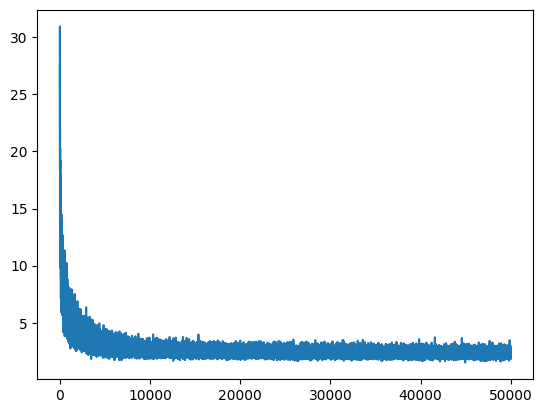

In [161]:
plt.plot(stepi, lossi)

In [162]:
emb = C[X_train]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)  # (32, 100)
logits = h @ W2 + b2  # (32, 27)
loss = F.cross_entropy(logits, Y_train)
loss

tensor(2.3481, grad_fn=<NllLossBackward0>)

In [163]:
emb = C[X_valid]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)  # (32, 100)
logits = h @ W2 + b2  # (32, 27)
loss = F.cross_entropy(logits, Y_valid)
loss

tensor(2.3635, grad_fn=<NllLossBackward0>)

In [164]:
# training split, dev/validation split, test split
# 80%, 10%, 10%


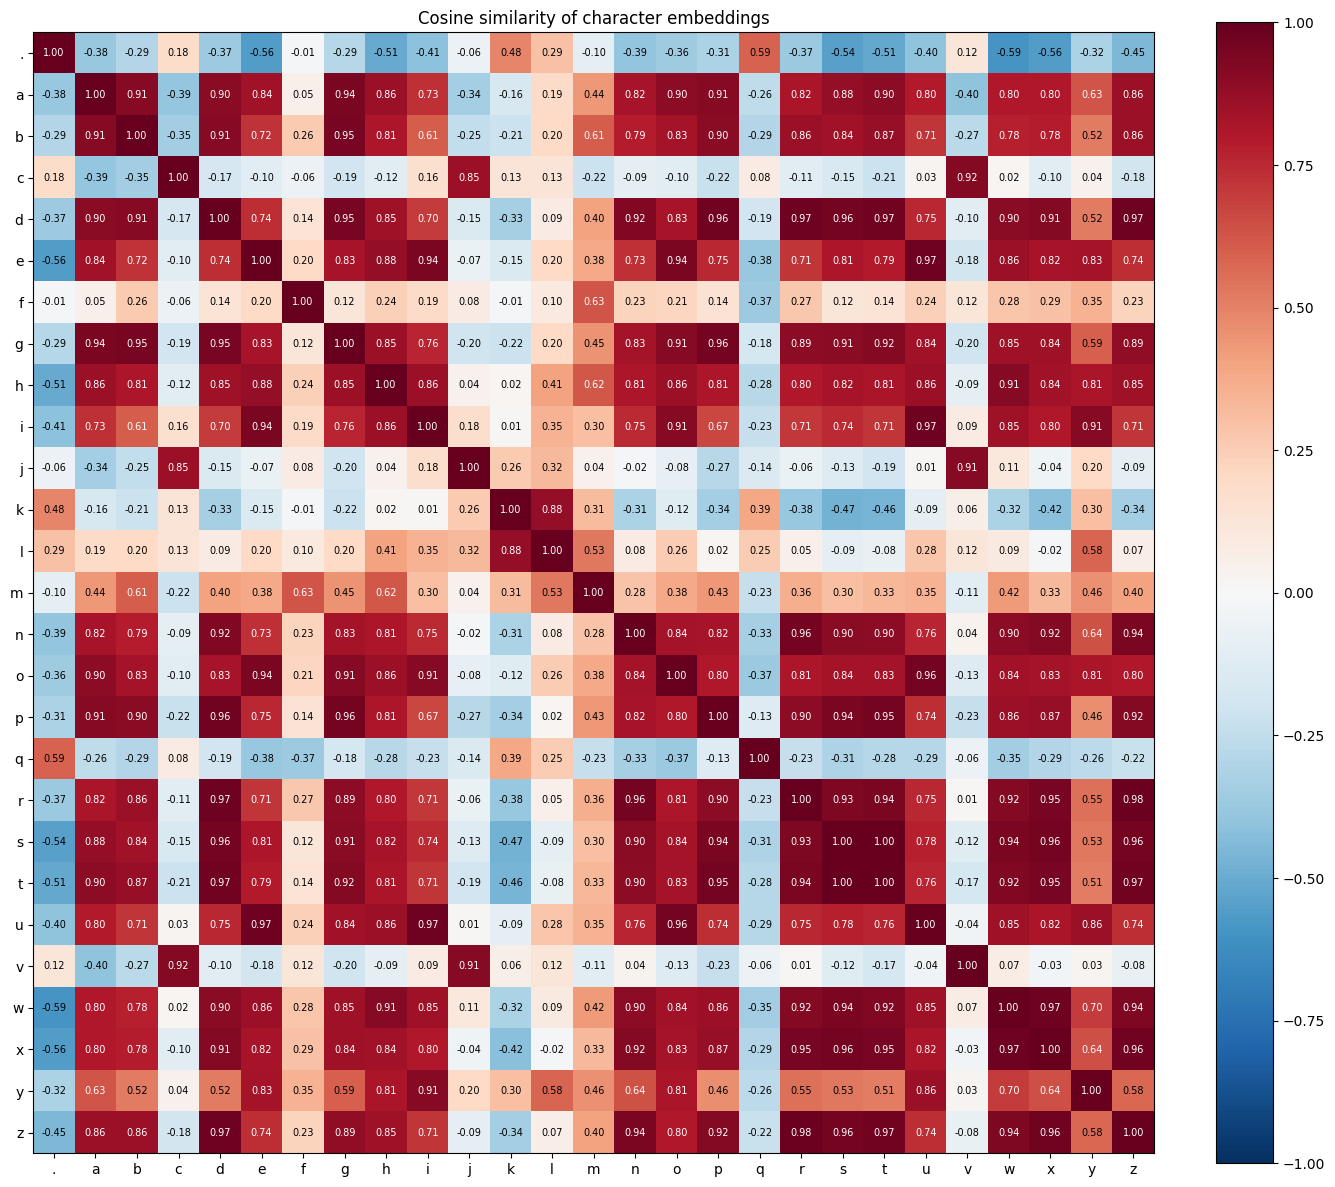

In [165]:
import torch.nn.functional as F

Cn = F.normalize(C, dim=1)   # 每一行除以它自己的长度
cos_sim = Cn @ Cn.T          # (27, 27)，值在 [-1, 1]

import matplotlib.pyplot as plt
import torch.nn.functional as F

Cn = F.normalize(C.detach(), dim=1)
sim = Cn @ Cn.T

labels = [itos[i] for i in range(27)]

plt.figure(figsize=(16, 16))   # 27×27=729 个格子，图要画大一点
plt.imshow(sim, cmap='RdBu_r', vmin=-1, vmax=1)
plt.colorbar(fraction=0.046)
plt.xticks(range(27), labels)
plt.yticks(range(27), labels)

for i in range(27):
    for j in range(27):
        v = sim[i, j].item()
        plt.text(j, i, f'{v:.2f}',
                 ha='center', va='center', fontsize=7,
                 color='white' if abs(v) > 0.6 else 'black')

plt.title('Cosine similarity of character embeddings')
plt.show()

In [167]:
# sample from the model
g = torch.Generator().manual_seed(2147483647)

for i in range(20):
    out = []
    context = [0] * (block_size-1) + [i]  # initialize with all ...
    out.append(i)
    while True:
        emb = C[torch.tensor([context])]   # (1, block_size, d)
        h = torch.tanh(emb.view(1, -1) @ W1 + b1)
        logits = h @ W2 + b2
        # probs = F.softmax(logits, dim=1)
        # ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        ix = torch.argmax(logits, dim=1).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break

    print(''.join(itos[i] for i in out))
        

.alle.
alle.
braya.
carlet.
daya.
elin.
fat.
gariel.
halle.
illa.
jan.
kailynn.
lana.
mariel.
nolana.
olana.
pariel.
quin.
ror.
saleya.
